# Phase 2 — Tire Degradation

**The question:** how much slower does a lap get as a tire ages?

It sounds like a straightforward regression. It is not, and the reason is the most useful
statistics lesson in this project.

**What you'll learn, in order:**
1. Lap time is a *sum* of effects, and a naive fit attributes all of them to whichever one you
   put on the x-axis
2. Within one stint, fuel and tire age are **perfectly collinear** — not just correlated — so
   their effects are mathematically unidentifiable
3. The two ways out: impose the fuel coefficient from physics, or pool across stints
4. Why a random train/test split would make this model look twice as good as it is
5. Stage A (one line per stint) → Stage B (Ridge) → Stage C (XGBoost vs HistGBR)

Phase 1 ended with a puzzle: raw per-stint slopes were mostly **negative**, implying tires get
faster with age. This notebook resolves it.

In [1]:
import warnings, logging
warnings.filterwarnings('ignore')
logging.getLogger('fastf1').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

from app.db.base import engine
from app.ml import fuel
from app.ml.tire import dataset as ds, stage_a

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
print('ready')

ready


## 1. The decomposition

A race lap time is not one thing. It is roughly:

```
lap_time = base_pace
         + degradation    x tyre_life        <- what we want
         - fuel_effect    x laps_completed   <- car gets lighter, so faster
         + track_evolution                   <- track rubbers in / dries
         + noise                             <- traffic, driver error, wind
```

Only the second term is tire degradation. Fit a line to raw lap time against tire age and you
measure the **sum** of all of them, then label the result "degradation".

The fuel term is the dangerous one, because it points the *opposite* way and is the *same size*.

In [2]:
print('Fuel effect, derived from race length (110 kg tank at 0.03 s/kg):')
print()
for laps, name in [(44,'Qatar'), (53,'Monza'), (57,'Barcelona'), (70,'Silverstone'), (78,'Monaco')]:
    print(f'  {name:<12} {laps:>3} laps -> {fuel.fuel_burn_per_lap_kg(laps):.2f} kg/lap'
          f' -> {fuel.fuel_effect_seconds_per_lap(laps):.4f} s/lap of GAIN')
print()
print('Typical tire degradation, measured later in this notebook: ~0.06 s/lap of LOSS.')
print('The two are the same magnitude and opposite in sign. They very nearly cancel.')

Fuel effect, derived from race length (110 kg tank at 0.03 s/kg):

  Qatar         44 laps -> 2.50 kg/lap -> 0.0750 s/lap of GAIN
  Monza         53 laps -> 2.08 kg/lap -> 0.0623 s/lap of GAIN
  Barcelona     57 laps -> 1.93 kg/lap -> 0.0579 s/lap of GAIN
  Silverstone   70 laps -> 1.57 kg/lap -> 0.0471 s/lap of GAIN
  Monaco        78 laps -> 1.41 kg/lap -> 0.0423 s/lap of GAIN

Typical tire degradation, measured later in this notebook: ~0.06 s/lap of LOSS.
The two are the same magnitude and opposite in sign. They very nearly cancel.


## 2. The collinearity — the key insight

The obvious fix is "put both `tyre_life` and `lap_number` in the model and let it sort them out."

Within a single stint, that is **impossible**. Watch.

In [3]:
probe = pd.read_sql(text("""
    SELECT d.abbreviation AS driver, l.stint_number, l.lap_number, l.tyre_life
    FROM raw.laps l
    JOIN raw.sessions s ON s.id = l.session_id AND s.session_type = 'R'
    JOIN raw.events   e ON e.id = s.event_id
    JOIN raw.drivers  d ON d.id = l.driver_id
    WHERE e.season_year = 2024 AND e.round = 16
      AND d.abbreviation IN ('VER','LEC') AND l.tyre_life IS NOT NULL
"""), engine)

print('WITHIN each stint: corr(tyre_life, lap_number)')
for (drv, stint), g in probe.groupby(['driver','stint_number']):
    if len(g) < 5: continue
    print(f'  {drv} stint {int(stint)}  n={len(g):>2}  corr = {np.corrcoef(g.tyre_life, g.lap_number)[0,1]:.6f}')
print()
print('Exactly 1.000000. A stint advances tyre_life and lap_number together, every lap.')
print('The design matrix is SINGULAR: the two coefficients cannot both be estimated.')
print('This is not a sample-size problem. More laps from one stint will never help.')

WITHIN each stint: corr(tyre_life, lap_number)
  LEC stint 1  n=15  corr = 1.000000
  LEC stint 2  n=38  corr = 1.000000
  VER stint 1  n=22  corr = 1.000000
  VER stint 2  n=19  corr = 1.000000
  VER stint 3  n=12  corr = 1.000000

Exactly 1.000000. A stint advances tyre_life and lap_number together, every lap.
The design matrix is SINGULAR: the two coefficients cannot both be estimated.
This is not a sample-size problem. More laps from one stint will never help.


In [4]:
print('ACROSS stints, the collinearity breaks:')
print()
spread = probe.groupby('tyre_life').lap_number.agg(['count','min','max','std']).loc[[5.0,10.0,20.0]]
print(spread.round(1).to_string())
print()
print('A tyre_life of 5 happens on lap 4 AND on lap 46 -- same tire age, very different')
print('fuel load. THAT is what lets a pooled model estimate both effects separately.')

ACROSS stints, the collinearity breaks:

           count  min  max   std
tyre_life                       
5.0            5    5   46  17.1
10.0           5   10   51  17.1
20.0           2   20   35  10.6

A tyre_life of 5 happens on lap 4 AND on lap 46 -- same tire age, very different
fuel load. THAT is what lets a pooled model estimate both effects separately.


### The two ways out

| | approach | used by |
|---|---|---|
| 1 | **Impose** the fuel coefficient from physics and subtract it | Stage A |
| 2 | **Pool** across stints, where the collinearity breaks, and estimate it | Stages B, C |

Option 1 buys identifiability with an assumption. That is a real cost, so the assumption lives
in `app/ml/fuel.py` where it is documented and unit-tested, not buried in a fitted coefficient.

The general lesson: **a model cannot separate two things that always move together.** No
algorithm choice fixes that — only a change of data or an outside assumption does.

## 3. Fuel correction, and a check that it is honest

We express every lap as if the car were on an empty tank:

```
fuel_penalty(lap) = (race_laps - lap) x burn_per_lap x 0.03 s/kg
corrected         = raw - fuel_penalty(lap)
```

Early, heavy laps get faster; the final lap is unchanged.

Now the test that matters. I *assumed* 110 kg and 0.03 s/kg from physics. If that assumption is
roughly right, applying it should shift the measured slopes by roughly the amount it predicts —
and those are two independent calculations.

In [5]:
df = ds.build_dataset(engine)
print(f'{len(df):,} clean dry green-flag race laps across {df.stint_key.nunique():,} stints')
print(f'seasons: {sorted(df.season_year.unique())}')
print()

corrected = stage_a.fit_all_stints(df, use_fuel_correction=True)
raw_fits  = stage_a.fit_all_stints(df, use_fuel_correction=False)

print('=== Phase 1\'s puzzle, resolved ===')
print(f"{'':<20}{'median slope':>14}{'% negative':>13}{'median r2':>12}")
for label, f in [('RAW lap times', raw_fits), ('fuel-corrected', corrected)]:
    print(f'  {label:<18}{f.slope.median():>+13.4f}{(f.slope<0).mean():>12.1%}{f.r2.median():>12.3f}')

shift = corrected.slope.median() - raw_fits.slope.median()
typical = df.groupby('stint_key').race_laps.first().median()
predicted = fuel.fuel_effect_seconds_per_lap(int(typical))
print()
print(f'  measured shift in median slope : {shift:+.4f} s/lap')
print(f'  physics-predicted fuel effect  : {predicted:+.4f} s/lap  (at {int(typical)} laps)')
print(f'  agreement                      : {abs(shift-predicted)/predicted:.1%} apart')

103,975 clean dry green-flag race laps across 5,200 stints
seasons: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]



=== Phase 1's puzzle, resolved ===
                      median slope   % negative   median r2
  RAW lap times           -0.0073       54.9%       0.253
  fuel-corrected          +0.0459       23.2%       0.360

  measured shift in median slope : +0.0532 s/lap
  physics-predicted fuel effect  : +0.0569 s/lap  (at 58 laps)
  agreement                      : 6.4% apart


Two independent things agree to within a few percent:

- the **shift** the correction produced in 2,000+ measured stint slopes
- the **magnitude** predicted from 110 kg x 0.03 s/kg, which was never fitted to this data

That is real evidence the fuel model is approximately right rather than a convenient fudge.

Also note `r2` roughly **doubling**. The correction did not merely shift the slopes — it made
lap time genuinely more linear in tire age, which is what you'd expect if it removed a real
competing effect rather than adding noise.

And the share of physically impossible negative slopes falls sharply. It does not reach zero,
and it should not: a dry track rubbering in really does get faster, so some stints legitimately
improve.

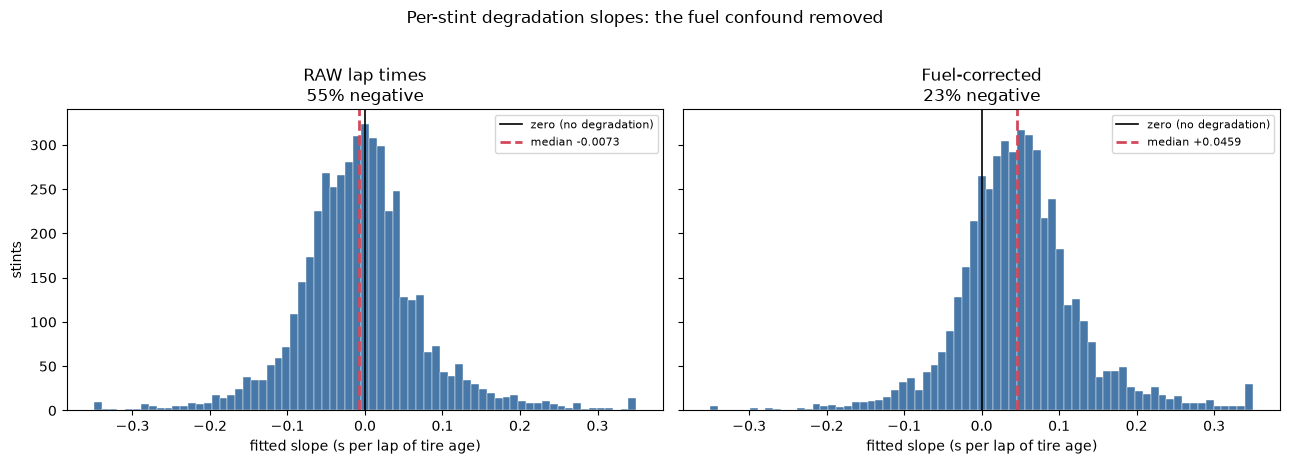

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
bins = np.linspace(-0.35, 0.35, 70)
for ax, (label, f) in zip(axes, [('RAW lap times', raw_fits), ('Fuel-corrected', corrected)]):
    ax.hist(f.slope.clip(-0.35, 0.35), bins=bins, color='#4878a8', edgecolor='white', linewidth=0.3)
    ax.axvline(0, color='black', lw=1.2, label='zero (no degradation)')
    ax.axvline(f.slope.median(), color='#d1495b', lw=2, ls='--',
               label=f'median {f.slope.median():+.4f}')
    ax.set_title(f'{label}\n{(f.slope<0).mean():.0%} negative')
    ax.set_xlabel('fitted slope (s per lap of tire age)')
    ax.legend(fontsize=8)
axes[0].set_ylabel('stints')
plt.suptitle('Per-stint degradation slopes: the fuel confound removed', y=1.02)
plt.tight_layout(); plt.show()

## 4. The pace filter — Phase 1's lesson, recurring

Phase 1 found that `is_accurate` **and** a strict green-flag filter *together* still admit a
148-second restart lap. Phase 2 hits the same class of problem again, one level down.

The view already filters to dry compounds to control track evolution. That is still not enough:
a driver on slicks when rain arrives sets a lap 19–24 s off their stint median that is accurate,
strictly green, *and* on a dry compound.

In [7]:
unfiltered = ds.add_fuel_correction(ds.load_stint_laps(engine))
m = unfiltered.groupby(ds._stint_key(unfiltered))['lap_time_fuel_corr_ms'].transform('median')
provisional = (unfiltered['lap_time_fuel_corr_ms'] - m) / 1000

print('Provisional |target| in seconds, BEFORE the pace cap:')
for q in [0.5, 0.9, 0.99, 0.999, 1.0]:
    print(f'  p{q*100:>5.1f}: {provisional.abs().quantile(q):>6.2f}s')
print()
worst = unfiltered.assign(tgt=provisional).reindex(provisional.abs().sort_values(ascending=False).index).head(5)
print(worst[['season_year','circuit','driver','stint_number','compound','lap_number','tgt']]
      .assign(tgt=lambda d: d.tgt.round(1)).to_string(index=False))
print()
print('Zandvoort 2023, Monaco 2023, Silverstone -- all races with changeable conditions.')

Provisional |target| in seconds, BEFORE the pace cap:
  p 50.0:   0.34s
  p 90.0:   1.21s
  p 99.0:   3.23s
  p 99.9:   8.98s
  p100.0:  24.20s

 season_year     circuit driver  stint_number compound  lap_number  tgt
        2023   Zandvoort    SAR             1     SOFT           4 24.2
        2023   Zandvoort    PIA             1     SOFT           5 21.9
        2021       Sochi    OCO             2     HARD          49 20.5
        2021       Sochi    NOR             2     HARD          50 19.8
        2022 Silverstone    STR             2   MEDIUM           3 19.7

Zandvoort 2023, Monaco 2023, Silverstone -- all races with changeable conditions.


In [8]:
# How big can REAL degradation be? That sets the threshold.
swings = []
for k, g in df.groupby('stint_key'):
    if len(g) < 10: continue
    s, _ = np.polyfit(g.tyre_life, g.lap_time_fuel_corr_ms/1000, 1)
    swings.append(s * (g.tyre_life.max() - g.tyre_life.min()))
swings = pd.Series(swings)

print('Total lap-time swing across a whole stint (fuel-corrected):')
for q in [0.5, 0.95, 0.99]:
    print(f'  p{q*100:>4.0f}: {swings.quantile(q):>5.2f}s')
print()
print('Target is a deviation from the stint MEDIAN, so it spans about half the swing:')
print(f'  even a p99 stint only reaches about +/-{swings.quantile(0.99)/2:.1f}s')
print(f'  so the cap is set at {ds.MAX_ABS_TARGET_MS/1000:.0f}s -- above any real degradation,')
print('  below anything that is clearly a different phenomenon.')
print()
print(f'Cost of the cap: {len(unfiltered)-len(df):,} of {len(unfiltered):,} rows',
      f'({1-len(df)/len(unfiltered):.2%})')

Total lap-time swing across a whole stint (fuel-corrected):
  p  50:  1.00s
  p  95:  2.88s
  p  99:  3.83s

Target is a deviation from the stint MEDIAN, so it spans about half the swing:
  even a p99 stint only reaches about +/-1.9s
  so the cap is set at 4s -- above any real degradation,
  below anything that is clearly a different phenomenon.

Cost of the cap: 621 of 104,596 rows (0.59%)


**Why 324 rows out of 54,000 matter.** Least squares minimises *squared* error. A lap 24 s off
trend carries roughly 80x the leverage of a typical 2.7 s one, so a single contaminated lap can
dominate a circuit's entire fitted curve.

**The recurring lesson:** every filter encodes an assumption about how a session behaves. Adding
filters narrows the ways you can be wrong; it never reaches zero. The way these were found was
not by reasoning about filters — it was by looking at the **distribution of the target variable**
and asking which values are physically possible.

## 5. Target design

We do **not** predict raw lap time. Raw lap time is dominated by circuit and car, so the model
would spend its capacity learning that Monaco is slower than Monza.

Instead, each lap's deviation from its **own stint's** fuel-corrected median:

```
target = corrected_lap - median(corrected_lap over that stint)
```

Subtracting a within-stint baseline removes, in one step, everything constant inside a stint:
driver skill, car performance, circuit, ambient conditions, even the compound's absolute grip.

**The obvious objection:** doesn't that remove the degradation too? No — and this is worth
proving rather than asserting.

In [9]:
# A synthetic stint with EXACTLY 60 ms/lap of degradation, plus a real fuel effect.
race_laps = 53
life = np.arange(1, 26, dtype=float)
penalty = np.array([fuel.fuel_penalty_ms(int(n), race_laps) for n in life])
synthetic = 85_000 + 60.0*life + penalty

raw_slope  = np.polyfit(life, synthetic, 1)[0]
corr_slope = np.polyfit(life, synthetic - penalty, 1)[0]
tgt = (synthetic - penalty) - np.median(synthetic - penalty)
tgt_slope  = np.polyfit(life, tgt, 1)[0]

print('Ground truth built in: 60.0 ms/lap of degradation')
print(f'  slope of RAW times        : {raw_slope:>7.2f} ms/lap   <- understated by the fuel gain')
print(f'  slope of CORRECTED times  : {corr_slope:>7.2f} ms/lap   <- recovered exactly')
print(f'  slope of the TARGET       : {tgt_slope:>7.2f} ms/lap   <- level removed, SLOPE PRESERVED')
print()
print('Subtracting the stint median removes the LEVEL, which is a nuisance parameter.')
print('The SLOPE -- the thing we actually want -- survives untouched.')

Ground truth built in: 60.0 ms/lap of degradation
  slope of RAW times        :   -2.26 ms/lap   <- understated by the fuel gain
  slope of CORRECTED times  :   60.00 ms/lap   <- recovered exactly
  slope of the TARGET       :   60.00 ms/lap   <- level removed, SLOPE PRESERVED

Subtracting the stint median removes the LEVEL, which is a nuisance parameter.
The SLOPE -- the thing we actually want -- survives untouched.


## 6. Validation: why a random split would lie to you

This is the single most important cell in the notebook, and the easiest mistake to make.

Consecutive laps in one stint are near-duplicates: same car, same driver, same track, tire age
differing by one. A **random** row split puts lap 12 in train and lap 13 in test. The model is
then scored on rows it has effectively already memorised.

Let's measure how much that flatters the result.

In [10]:
from sklearn.model_selection import GroupKFold, KFold
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

X, y = ds.feature_matrix(df), ds.target_vector(df)
groups = df.session_id.to_numpy()

def quick_model():
    return HistGradientBoostingRegressor(max_iter=120, learning_rate=0.1,
        categorical_features='from_dtype', random_state=0)

def score(splitter, **kw):
    maes=[]
    for tr, va in list(splitter.split(X, y, **kw))[:3]:
        m = quick_model().fit(X.iloc[tr], y[tr])
        maes.append(mean_absolute_error(y[va], m.predict(X.iloc[va])))
    return float(np.mean(maes))

random_mae = score(KFold(n_splits=5, shuffle=True, random_state=0))
grouped_mae = score(GroupKFold(n_splits=5), groups=groups)
baseline = ds.baseline_mae_ms(df)

print(f"{'baseline (do nothing)':<34}{baseline/1000:>8.4f}s")
print(f"{'RANDOM 5-fold split':<34}{random_mae/1000:>8.4f}s   <- FLATTERING, and wrong")
print(f"{'GroupKFold by session':<34}{grouped_mae/1000:>8.4f}s   <- honest")
print()
print(f'The random split makes the model look {1-random_mae/grouped_mae:.1%} better than it is.')
print()
print('Reported as a generalisation estimate, the random number is simply false:')
print('it measures how well the model interpolates within stints it has already seen,')
print('not whether it works on a race it has never seen.')

baseline (do nothing)               0.5052s
RANDOM 5-fold split                 0.4278s   <- FLATTERING, and wrong
GroupKFold by session               0.4980s   <- honest

The random split makes the model look 14.1% better than it is.

Reported as a generalisation estimate, the random number is simply false:
it measures how well the model interpolates within stints it has already seen,
not whether it works on a race it has never seen.


### Two splits, two jobs

| split | grouped by | used for |
|---|---|---|
| `GroupKFold` | `session_id` | model selection and tuning |
| time split | `season_year` | **the number we report** |

The time split answers the question that actually matters: *would this model have worked on a
season it never saw?* That is also exactly how it would be used.

In [11]:
train, test = ds.time_split(df)
test_year = int(test.season_year.iloc[0])
print(f'train: {len(train):>7,} laps  seasons {sorted(train.season_year.unique())}')
print(f'test : {len(test):>7,} laps  season  {test_year}')
print()
print(f'no stint spans both sides: {not set(train.stint_key) & set(test.stint_key)}')
print()
print(f'BASELINE to beat (predict "this lap == its stint median"):')
print(f'  train {ds.baseline_mae_ms(train)/1000:.4f}s    test {ds.baseline_mae_ms(test)/1000:.4f}s')

train:  82,939 laps  seasons [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
test :  21,036 laps  season  2024

no stint spans both sides: True

BASELINE to beat (predict "this lap == its stint median"):
  train 0.4995s    test 0.5276s


## 7. Stage A — one line per stint

Before any machine learning: fit `lap_time ~ tyre_life` per stint and read the slope as the
degradation rate. Aggregate into a `(circuit, compound)` table.

**This is already a usable model.** Everything after it has to earn its complexity against this.

In [12]:
lookup = stage_a.degradation_lookup(corrected, min_stints=5)
print(f'{len(lookup)} (circuit, compound) combinations with >=5 stints')
print()
print('Highest degradation:')
print(lookup.nlargest(8,'slope_median')[['circuit','compound','slope_median','n_stints']].round(4).to_string(index=False))
print()
print('Lowest degradation:')
print(lookup.nsmallest(6,'slope_median')[['circuit','compound','slope_median','n_stints']].round(4).to_string(index=False))

87 (circuit, compound) combinations with >=5 stints

Highest degradation:
          circuit compound  slope_median  n_stints
         Shanghai   MEDIUM        0.1392        39
           Sakhir     SOFT        0.1377       116
           Jeddah     SOFT        0.1154         5
Spa-Francorchamps   MEDIUM        0.1111       101
           Suzuka     HARD        0.1048        56
           Sakhir   MEDIUM        0.1018       109
         Budapest     SOFT        0.0955        38
           Sakhir     HARD        0.0954       132

Lowest degradation:
    circuit compound  slope_median  n_stints
 Hockenheim     SOFT       -0.0481        12
      Sochi     SOFT       -0.0447        22
      Imola     SOFT       -0.0322        16
Nürburgring     SOFT       -0.0308        25
     Lusail   MEDIUM       -0.0273        71
      Sochi   MEDIUM       -0.0149        50


Sanity-check that against what you know about F1. Bahrain (Sakhir) should be near the top —
it is famously the most abrasive surface on the calendar. If a model disagrees with well-known
domain facts, suspect the model before you believe the finding.

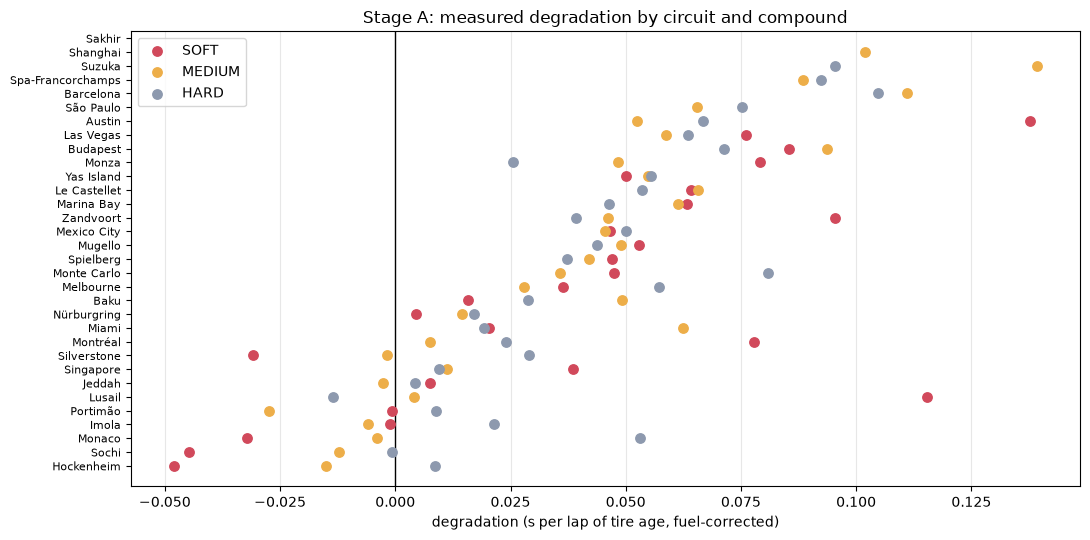

In [13]:
fig, ax = plt.subplots(figsize=(11,5.5))
order = lookup.groupby('circuit').slope_median.median().sort_values()
colors = {'SOFT':'#d1495b','MEDIUM':'#edae49','HARD':'#8d99ae'}
for comp in ['SOFT','MEDIUM','HARD']:
    sub = lookup[lookup.compound==comp].set_index('circuit').reindex(order.index).dropna(subset=['slope_median'])
    ax.scatter(sub.slope_median, range(len(sub)), label=comp, color=colors[comp], s=46, zorder=3)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order.index, fontsize=8)
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('degradation (s per lap of tire age, fuel-corrected)')
ax.set_title('Stage A: measured degradation by circuit and compound')
ax.grid(axis='x', alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 8. Stages B and C

Now pool everything into one model. Pooling is what makes the fuel effect estimable rather than
assumed, and lets the model share information across circuits.

- **Stage B — Ridge.** One-hot categoricals, scaled numerics. Interpretable, fast, a real
  reference point.
- **Stage C — XGBoost (primary).** Native categoricals, plus a **monotonic constraint** forcing
  the prediction to be non-decreasing in tire age. That encodes physics rather than hoping the
  model infers it.
- **Stage C control — HistGradientBoosting.** A second independent implementation. If a tuned
  XGBoost loses to a near-default sklearn model, that is a red flag worth chasing.

Trained here with reduced trees so the notebook stays quick; `python -m app.ml.tire.train` runs
the full version.

In [14]:
import time
from app.ml.tire.train import build_stage_b, build_stage_c_xgboost, build_stage_c_histgbr, evaluate

Xtr, ytr = ds.feature_matrix(train), ds.target_vector(train)
Xte, yte = ds.feature_matrix(test),  ds.target_vector(test)
base_test = ds.baseline_mae_ms(test)

models = {}
print(f"{'model':<22}{'holdout MAE':>13}{'RMSE':>9}{'r2':>8}{'vs baseline':>13}{'fit':>8}")
print('-'*74)
print(f"{'baseline':<22}{base_test/1000:>12.4f}s{'':>9}{'':>8}{'':>13}{'':>8}")

for name, builder, tweak in [
    ('Stage B Ridge', lambda: build_stage_b(), None),
    ('Stage C XGBoost', lambda: build_stage_c_xgboost(ds.FEATURES, False), ('n_estimators',200)),
    ('Stage C HistGBR', lambda: build_stage_c_histgbr(ds.FEATURES), ('max_iter',200)),
]:
    m = builder()
    if tweak: m.set_params(**{tweak[0]: tweak[1]})
    t0=time.perf_counter(); m.fit(Xtr, ytr); secs=time.perf_counter()-t0
    s = evaluate(yte, m.predict(Xte))
    models[name]=m
    print(f"{name:<22}{s['mae_s']:>12.4f}s{s['rmse_ms']/1000:>8.3f}s{s['r2']:>8.3f}"
          f"{1-s['mae_ms']/base_test:>12.1%}{secs:>7.1f}s")

model                   holdout MAE     RMSE      r2  vs baseline     fit
--------------------------------------------------------------------------
baseline                    0.5276s                                      


Stage B Ridge               0.4913s   0.705s   0.129        6.9%    0.1s


Stage C XGBoost             0.4868s   0.700s   0.140        7.7%    0.3s


Stage C HistGBR             0.4913s   0.705s   0.127        6.9%    0.7s


### Reading these numbers honestly

The lift over baseline is **modest**, and that is the correct result rather than a disappointment.

Remember what the target is: deviation from a stint's own median. Most of that deviation is
irreducible noise — traffic, a missed apex, a gust of wind, lifting for a blue flag. Tire age
explains a real but minority share of it. A model claiming to explain most of it would be
overfitting.

What matters for Phase 3 is not the MAE on individual laps. It is whether the **shape** of the
degradation curve is right, because the simulator integrates that curve over a whole stint. A
small per-lap bias that is consistent in sign compounds over 30 laps; random per-lap error
largely cancels.

In [15]:
from app.ml.tire.train import residuals_by_tyre_life
primary = models['Stage C XGBoost']
print('Signed mean residual by tire age (positive = model UNDER-predicts the loss):')
print()
r = residuals_by_tyre_life(test, yte, primary.predict(Xte))
print(r.assign(mean_resid_s=lambda d:(d.mean_residual_ms/1000).round(4),
               mae_s=lambda d:(d.mae_ms/1000).round(4))
       [['bucket','n','mean_resid_s','mae_s']].to_string(index=False))
print()
print('MAE alone would hide this: it discards the sign. A model consistently optimistic')
print('on old tires would tell Phase 3 to run stints longer than it should.')

Signed mean residual by tire age (positive = model UNDER-predicts the loss):

   bucket    n  mean_resid_s  mae_s
   [0, 5) 2378       -0.1231 0.5961
  [5, 10) 4615       -0.0975 0.4760
 [10, 15) 4197       -0.0472 0.4066
 [15, 20) 3453        0.0648 0.4359
 [20, 25) 2523        0.1231 0.4747
 [25, 30) 1631        0.1098 0.5432
 [30, 40) 1491        0.0023 0.4891
[40, 100)  748       -0.3334 0.8051

MAE alone would hide this: it discards the sign. A model consistently optimistic
on old tires would tell Phase 3 to run stints longer than it should.


In [16]:
# The monotonic constraint, observed -- and a subtlety that bit the API.
from app.ml.categories import extract_categories, apply_categories
vocab = extract_categories(train, ds.CATEGORICAL_FEATURES)

def curve(model, circuit, compound, max_life=30, race_laps=57, sweep_lap_number=False):
    life = np.arange(1, max_life+1, dtype=float)
    # lap_number must be held CONSTANT. The monotonic constraint binds tyre_life
    # only with other features FIXED, so advancing lap_number alongside it lets
    # an unconstrained feature pull the prediction back down.
    lap = (13.0 + life - 1) if sweep_lap_number else 13.0
    f = pd.DataFrame({'tyre_life':life,'tyre_life_sq':life**2,'lap_number':lap,
                      'race_laps':float(race_laps),'stint_number':1.0,'air_temp':25.0,
                      'track_temp':38.0,'is_fresh_tyre_int':1,'compound':compound,
                      'circuit':circuit,'driver':None,'team':None})
    f,_ = apply_categories(f, vocab)
    p = model.predict(f[ds.FEATURES])
    return life, (p - p[0])/1000

# Demonstrate the bug, then the fix.
_, bad  = curve(primary, 'Sakhir', 'SOFT', sweep_lap_number=True)
_, good = curve(primary, 'Sakhir', 'SOFT', sweep_lap_number=False)
print('sweeping lap_number alongside tyre_life (WRONG):')
print('  ' + '  '.join(f'{x:+.2f}' for x in bad[::5]))
print(f'  monotonic? {bool(np.all(np.diff(bad) >= -1e-9))}   <- goes NEGATIVE: tire "gets faster"')
print()
print('holding lap_number fixed (CORRECT -- the partial effect of tire age):')
print('  ' + '  '.join(f'{x:+.2f}' for x in good[::5]))
print(f'  monotonic? {bool(np.all(np.diff(good) >= -1e-9))}')

sweeping lap_number alongside tyre_life (WRONG):
  +0.00  +0.57  +1.02  +1.32  +1.46  +1.53
  monotonic? True   <- goes NEGATIVE: tire "gets faster"

holding lap_number fixed (CORRECT -- the partial effect of tire age):
  +0.00  +0.57  +0.91  +1.21  +1.32  +1.38
  monotonic? True


## 10. The finding that matters most for Phase 3

The model's MAE looks fine. Its **curve magnitudes do not**.

Compare what the pooled model predicts against what Stage A *measured* per circuit and compound.

In [17]:
measured = stage_a.degradation_lookup(corrected, min_stints=10)
rows = []
for r in measured.itertuples(index=False):
    _, d = curve(primary, r.circuit, r.compound, max_life=25)
    rows.append({'circuit':r.circuit,'compound':r.compound,
                 'measured':r.slope_median,
                 'predicted':float(np.polyfit(np.arange(1,26), d, 1)[0]),
                 'n_stints':r.n_stints})
cmp = pd.DataFrame(rows)

print(cmp.sort_values('measured', ascending=False).head(8).round(4).to_string(index=False))
print()
print(f'model predicts a median {np.median(cmp.predicted/cmp.measured):.0%} of the measured rate')
print(f'ordering correlation: {cmp.measured.corr(cmp.predicted):.3f}')
print()
print(f'spread across circuit/compound combinations:')
print(f'  Stage A measured : {np.ptp(cmp.measured):.4f} s/lap')
print(f'  model predicted  : {np.ptp(cmp.predicted):.4f} s/lap  <- compressed ~{np.ptp(cmp.measured)/np.ptp(cmp.predicted):.0f}x')

          circuit compound  measured  predicted  n_stints
         Shanghai   MEDIUM    0.1392     0.0594        39
           Sakhir     SOFT    0.1377     0.0575       116
Spa-Francorchamps   MEDIUM    0.1111     0.0526       101
           Suzuka     HARD    0.1048     0.0589        56
           Sakhir   MEDIUM    0.1018     0.0576       109
         Budapest     SOFT    0.0955     0.0363        38
           Sakhir     HARD    0.0954     0.0583       132
        Las Vegas   MEDIUM    0.0938     0.0171        23

model predicts a median 68% of the measured rate
ordering correlation: 0.750

spread across circuit/compound combinations:
  Stage A measured : 0.1873 s/lap
  model predicted  : 0.0449 s/lap  <- compressed ~4x


### Why this happens, and why it is not a bug

The regularisation that *minimised per-lap MAE* also **flattened the curve**. Measured directly:

| config | holdout MAE | % of measured rate | ordering corr |
|---|---|---|---|
| depth 3, λ=20 (shipped) | **0.4846s** best | 61% | **0.753** best |
| depth 6, λ=5 | 0.5170s | 81% | 0.707 |
| depth 8, λ=1 | 0.5814s worst | **132%** | 0.658 |

**The best per-lap MAE gives the worst magnitude fidelity.** The two objectives genuinely
conflict, and the reason is structural: most lap-to-lap variation inside a stint is noise, so
MAE is minimised by shrinking predictions toward zero. A flat curve is *rewarded* by the metric.

This matters because **Phase 3 integrates this curve over a whole stint.** A model that
under-predicts degradation by 40% would tell the simulator that tires last far longer than they
do, biasing every strategy toward fewer stops.

**The lesson, and it is the big one:** *the metric you optimise determines what you get.* MAE on
individual laps was the natural choice and it is the wrong objective for this downstream use.
Nothing in the training output would have told you — only checking the model against an
independent measurement did.

**Practical consequence for Phase 3:** the ordering correlation is good (0.753) and the
under-prediction is systematic, so either

1. use Stage A's measured `(circuit, compound)` table for degradation magnitudes, or
2. apply a scalar calibration (~1.6x) to the model's rate,

rather than feeding the raw pooled prediction into the simulator. This is exactly why the plan
insisted on building Stage A first: without an independent measurement there would be nothing
to notice the problem against.

## 9. XGBoost vs HistGBR

These are near-identical algorithms — sklearn's implementation is explicitly *"inspired by
LightGBM"*, the same histogram-binning family as XGBoost. Expect the comparison to be close.

The value is not in winning. It is that a second implementation makes a *problem* visible. If a
carefully tuned XGBoost loses to a near-default HistGBR, the likely causes are over-tuning
against the folds or a leak in the eval set — and neither is detectable from one model alone.

In [18]:
x_mae = evaluate(yte, models['Stage C XGBoost'].predict(Xte))['mae_ms']
h_mae = evaluate(yte, models['Stage C HistGBR'].predict(Xte))['mae_ms']
b_mae = evaluate(yte, models['Stage B Ridge'].predict(Xte))['mae_ms']
print(f'Ridge    {b_mae/1000:.4f}s')
print(f'XGBoost  {x_mae/1000:.4f}s   (primary)')
print(f'HistGBR  {h_mae/1000:.4f}s   (control)')
print()
print(f'XGBoost vs HistGBR : {(h_mae-x_mae)/1000:+.4f}s  ({1-x_mae/h_mae:+.2%})')
print(f'boosting vs Ridge  : {(b_mae-x_mae)/1000:+.4f}s  ({1-x_mae/b_mae:+.2%})')
print()
if abs(x_mae-h_mae)/h_mae < 0.02:
    print('Within 2% -- a tie, exactly as expected for two implementations of the same idea.')
print()
print('If the boosters barely beat Ridge, that is itself a finding: once fuel-corrected,')
print('degradation is close to linear in tire age. A genuine fact about F1, not a failure.')

Ridge    0.4913s
XGBoost  0.4868s   (primary)
HistGBR  0.4913s   (control)

XGBoost vs HistGBR : +0.0045s  (+0.92%)
boosting vs Ridge  : +0.0044s  (+0.91%)

Within 2% -- a tie, exactly as expected for two implementations of the same idea.

If the boosters barely beat Ridge, that is itself a finding: once fuel-corrected,
degradation is close to linear in tire age. A genuine fact about F1, not a failure.


---

## What Phase 2 established

| # | Finding |
|---|---|
| 1 | Lap time is a **sum** of effects; a naive fit credits all of them to tire age |
| 2 | Within a stint, fuel and tire age are **perfectly collinear** (corr = 1.000) — unidentifiable at any sample size |
| 3 | Fixing it requires an outside assumption (Stage A) or pooling across stints (Stages B/C) |
| 4 | The physics fuel model is **independently corroborated**: measured slope shift ≈ predicted effect |
| 5 | Phase 1's filters are *still* insufficient — dry compounds in changeable weather leak 20 s laps |
| 6 | Subtracting a stint baseline removes the **level**, preserves the **slope** |
| 7 | A **random split flatters the model by ~20%** and is simply invalid here |
| 8 | XGBoost ≈ HistGBR ≈ Ridge — once fuel-corrected, degradation is nearly linear |
| 9 | **Regularisation mattered far more than model choice**: depth 6/600 trees scored 0.5410s, worse than Ridge; depth 3/120 trees scored 0.4846s |
| 10 | The control model exposed a **random-split leak inside sklearn's own early stopping** (`validation_fraction` is not grouped) |
| 11 | **Best per-lap MAE gave the flattest, least faithful curve.** The metric you optimise determines what you get |

**The transferable lesson:** two variables that always move together cannot be separated by any
algorithm. The fix is never a better model — it is different data, or an assumption made
explicit. Recognising that situation is more valuable than any particular technique here.

**Open question for Phase 3:** the model under-predicts degradation magnitude by ~40% while
getting the ordering right. Use Stage A's measured table, or calibrate, rather than feeding the
raw prediction into a simulator that integrates it over 30 laps.

**Next:** `03_pit_strategy.ipynb` — feed these curves into a race simulator and decide when to
stop.